In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update(
    {
        "font.size": 10,
        "axes.titlesize": 14,
        "axes.labelsize": 10,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 10,
        # embed TrueType fonts in PDF for consistent rendering
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        # use Computer Modern (mathtext + serif fallback)
        "font.family": "serif",
        "font.serif": ["Computer Modern", "DejaVu Serif"],
        "mathtext.fontset": "cm",
        # avoid requiring an external TeX installation by using mathtext
        "text.usetex": False,
    }
)

In [2]:
import os

import jax
import jax.numpy as jnp

os.environ["CUDA_VISIBLE_DEVICES"] = "3"

HORIZON = 10
INITIAL_STATE = jnp.array([3.0, 5.0])  # position, velocity

In [3]:
from hcnn.system_constraints import SystemConstraintsBall
from hcnn.training.train_bundle import TrainBundle

system = TrainBundle.build_double_integrator()

sys_constraints = SystemConstraintsBall.factory(
    center=jnp.array([6.5, 0]), radius=1.5, action_dim=1
)

In [4]:
gain_matrix = jnp.array([[0.2, 2 / 3]])

In [5]:
from hcnn.optimization_layer import Rollout


def scan_fn(state, _):
    action = -gain_matrix @ state
    next_state = system.sys_dynamics(state, action)
    return next_state, (state, action)


states, actions = jax.lax.scan(scan_fn, INITIAL_STATE, None, length=HORIZON)[1]

raw_rollout = Rollout(states, actions)

In [6]:
raw_rollout

Rollout(states=Array([[ 3.        ,  5.        ],
       [ 6.0333333 ,  1.0666666 ],
       [ 6.141111  , -0.8511112 ],
       [ 4.959593  , -1.5119259 ],
       [ 3.455683  , -1.4958938 ],
       [ 2.112852  , -1.1897678 ],
       [ 1.1083883 , -0.81915975],
       [ 0.451443  , -0.4947309 ],
       [ 0.07647809, -0.2551989 ],
       [-0.10130231, -0.10036191]], dtype=float32), actions=Array([[-3.9333334 ],
       [-1.9177778 ],
       [-0.66081476],
       [ 0.0160321 ],
       [ 0.306126  ],
       [ 0.37060812],
       [ 0.32442886],
       [ 0.239532  ],
       [ 0.15483698],
       [ 0.0871684 ]], dtype=float32))

In [7]:
from hcnn.optimization_layer import ProjectionPhi, ProjectionProblem
from hcnn.solver import SQPParameters

projection_problem = ProjectionProblem.factory(
    sys_dynamics=system.sys_dynamics,
    sys_constraints=sys_constraints,
    horizon=HORIZON,
)
phi = ProjectionPhi(
    states_ref=raw_rollout.states,
    actions_ref=raw_rollout.actions,
    initial_state=INITIAL_STATE,
)
sqp_problem = projection_problem.replace(phi=phi)
sqp_parameters = SQPParameters(
    max_iter_nonlin=10, ls_penalty_weight=100, tol_prim=1e-6, tol_dual=1e-6
)

In [8]:
# Manual SQP iterations to log residuals
from functools import partial

import jax.numpy as jnp

from hcnn.solver.solver_sqp import SQPVariables, sqp_step

# Initialize SQP variables
variables = SQPVariables.factory(problem=sqp_problem, parameters=sqp_parameters)

# Lists to store residuals
primal_residuals = []
dual_residuals = []

step_jit = jax.jit(
    partial(sqp_step, problem=sqp_problem, parameters=sqp_parameters)
)

for i in range(sqp_parameters.max_iter_nonlin):
    print(f"Iteration {i + 1}")
    variables = step_jit(variables)
    primal_residuals.append(variables.max_primal_residual)
    dual_residuals.append(variables.max_dual_residual)

# Convert lists to JAX arrays for plotting
primal_residuals = jnp.stack(primal_residuals)
dual_residuals = jnp.stack(dual_residuals)

# Extract final solution
x_star_manual = variables.x
optvar = projection_problem.x_to_optvar(x_star_manual)
proj_rollout = Rollout(
    states=optvar.states,
    actions=optvar.actions,
)

Iteration 1
osqp prim 4.589557647705078e-06, dual 1.0460615158081055e-05, iter 2000, mult 0.001953125, infeas False
SQP iter 1/10 | beta: 1.000e+00 | lin iters: 2000
Iteration 2
osqp prim 6.51925802230835e-07, dual 7.897614864305069e-07, iter 480, mult 0.03125, infeas False
SQP iter 2/10 | beta: 1.000e+00 | lin iters: 480
Iteration 3
osqp prim 2.1420419216156006e-07, dual 7.152557373046875e-07, iter 100, mult 1.0, infeas False
SQP iter 3/10 | beta: 1.000e+00 | lin iters: 100
Iteration 4
osqp prim 3.919849405065179e-07, dual 2.980232238769531e-07, iter 100, mult 1.0, infeas False
SQP iter 4/10 | beta: 1.000e+00 | lin iters: 100
Iteration 5
osqp prim 2.8023697495882516e-07, dual 2.384185791015625e-07, iter 100, mult 1.0, infeas False
SQP iter 5/10 | beta: 1.000e+00 | lin iters: 100
Iteration 6
osqp prim 2.956795412956126e-07, dual 4.76837158203125e-07, iter 100, mult 1.0, infeas False
SQP iter 6/10 | beta: 2.500e-01 | lin iters: 100
Iteration 7
osqp prim 2.6043926482088864e-07, dual 2.38

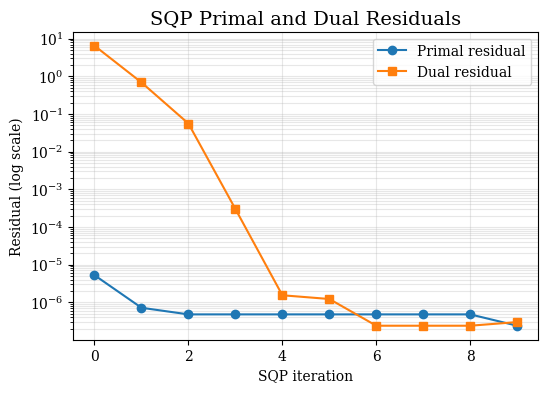

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(primal_residuals, label="Primal residual", marker="o")
ax.plot(dual_residuals, label="Dual residual", marker="s")
ax.set_yscale("log")
ax.set_xlabel("SQP iteration")
ax.set_ylabel("Residual (log scale)")
ax.set_title("SQP Primal and Dual Residuals")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()
fig.savefig("convergence_non_convex.pdf")

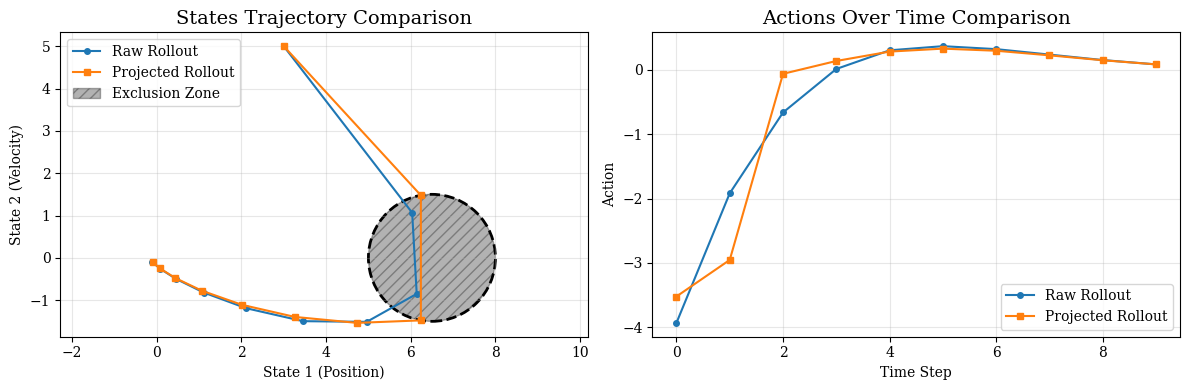

: 

In [ ]:
from matplotlib import pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Plot states comparison
ax1.plot(
    raw_rollout.states[:, 0],
    raw_rollout.states[:, 1],
    "o-",
    label="Raw Rollout",
    markersize=4,
    linewidth=1.5,
)
ax1.plot(
    proj_rollout.states[:, 0],
    proj_rollout.states[:, 1],
    "s-",
    label="Projected Rollout",
    markersize=4,
    linewidth=1.5,
)

# Plot the ball constraint (exclusion zone)
circle = plt.Circle(
    (sys_constraints.center[0], sys_constraints.center[1]),
    sys_constraints.radius,
    color="k",
    fill=True,
    alpha=0.3,
    label="Exclusion Zone",
    hatch="///",
)
ax1.add_patch(circle)

# Also add the boundary circle
circle_boundary = plt.Circle(
    (sys_constraints.center[0], sys_constraints.center[1]),
    sys_constraints.radius,
    color="k",
    fill=False,
    linewidth=2,
    linestyle="--",
)
ax1.add_patch(circle_boundary)

ax1.set_xlabel("State 1 (Position)")
ax1.set_ylabel("State 2 (Velocity)")
ax1.set_title("States Trajectory Comparison")
ax1.legend(loc="upper left")
ax1.axis("equal")
ax1.grid(True, alpha=0.3)

# Plot actions comparison
time_steps = range(len(raw_rollout.actions))
ax2.plot(
    time_steps,
    raw_rollout.actions[:, 0],
    "o-",
    label="Raw Rollout",
    markersize=4,
    linewidth=1.5,
)
ax2.plot(
    time_steps,
    proj_rollout.actions[:, 0],
    "s-",
    label="Projected Rollout",
    markersize=4,
    linewidth=1.5,
)
ax2.set_xlabel("Time Step")
ax2.set_ylabel("Action")
ax2.set_title("Actions Over Time Comparison")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
fig.savefig("trajectory_non_convex.pdf")